# Week 7 — At home: from a protein table to a result

**27200 Data-driven Bioengineering**

> **This notebook is for you to work through at home.** It is not part of the exercises in class.
> It takes about an hour.

At the end of a proteomics experiment you receive a table: one row per protein, one column per sample,
filled with intensities. A very common situation is to have that table and not know what to do with
it. This notebook goes through the usual steps — filtering, log transformation, missing values,
normalization, imputation, statistics — and shows what each one does to the result.

Normally you cannot check whether your analysis is right, because you do not know the true answer.
Here you can. The data is a benchmark
([Cox et al. 2014](https://doi.org/10.1074/mcp.M113.031591), PRIDE
[PXD000279](https://www.ebi.ac.uk/pride/archive/projects/PXD000279)):

- **HeLa lysate** (human) mixed with **E. coli lysate**
- two conditions, **L** and **H**, three replicates each
- the amount of HeLa is the **same** in L and H
- H contains **three times more E. coli** than L

So the right answer is known: human proteins should not change (log2 ratio 0), and E. coli proteins
should all go up by a factor of 3 (log2 ratio 1.58). Every human protein you call significant is a
false positive.

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

f = "maxlfq_hela_ecoli_proteinGroups.csv"
if not os.path.exists(f):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/UadKLab/27200_Data-Driven-Bioengineering/main/weeks/week07_proteomics/data/" + f, f)
pg = pd.read_csv(f)
print(pg.shape)
pg.head(3)

(6694, 17)


,Protein IDs,Majority protein IDs,Gene names,Fasta headers,Peptides,Razor + unique peptides,Unique peptides,Only identified by site,Reverse,Contaminant,LFQ intensity H1,LFQ intensity H2,LFQ intensity H3,LFQ intensity L1,LFQ intensity L2,LFQ intensity L3,Species
0,A0AV96;B7Z8Z7;A0AV96-2;D6R9D6;D6RBS9;D6REZ6;D6...,A0AV96;B7Z8Z7;A0AV96-2;D6R9D6,RBM47,>sp|A0AV96|RBM47_HUMAN RNA-binding protein 47 ...,13,13,13,NaN,NaN,NaN,166790000,176680000,140720000,202980000,245050000,259580000,Human
1,A0AVT1;A0AVT1-2;H0Y8S8;A0AVT1-4;A0AVT1-3,A0AVT1;A0AVT1-2,UBA6,>sp|A0AVT1|UBA6_HUMAN Ubiquitin-like modifier-...,14,14,14,NaN,NaN,NaN,34679000,46278000,24750000,72394000,71990000,58362000,Human
2,H7BXI1;A0FGR8-6;A0FGR8-2;A0FGR8;C9JGI7;A0FGR8-...,H7BXI1;A0FGR8-6;A0FGR8-2;A0FGR8;C9JGI7;A0FGR8-4,ESYT2,>tr|H7BXI1|H7BXI1_HUMAN Extended synaptotagmin...,11,11,11,NaN,NaN,NaN,56390000,55263000,58800000,85986000,101540000,91829000,Human


The table comes from MaxQuant, the search and quantification software that produced it. We kept the
columns you need:

| Column | Meaning |
|---|---|
| `Protein IDs` | all proteins that share the peptides of this row (a *protein group*) |
| `Peptides`, `Unique peptides` | how many peptides were seen |
| `Reverse` | `+` if the group is a decoy (the reversed sequences from Exercise 2) |
| `Contaminant` | `+` for common contaminants: keratin from skin, trypsin itself, serum proteins |
| `Only identified by site` | `+` if seen only through a modified peptide |
| `LFQ intensity L1 ... H3` | the label-free quantification value per sample; 0 means not measured |
| `Species` | added by us from the protein headers |

## 1 · Filter

In [2]:
lfq = [c for c in pg.columns if c.startswith("LFQ intensity")]
L = [c for c in lfq if c.endswith(("L1", "L2", "L3"))]
H = [c for c in lfq if c.endswith(("H1", "H2", "H3"))]

keep = (pg["Reverse"] != "+") & (pg["Contaminant"] != "+") & (pg["Only identified by site"] != "+") \
       & pg.Species.isin(["Human", "E. coli"])
print(f"removed: {(pg['Reverse'] == '+').sum()} decoys, {(pg['Contaminant'] == '+').sum()} contaminants, "
      f"{(pg['Only identified by site'] == '+').sum()} only-by-site")
d = pg[keep].copy()
print(f"kept {len(d)} protein groups:", d.Species.value_counts().to_dict())

removed: 84 decoys, 44 contaminants, 80 only-by-site
kept 6507 protein groups: {'Human': 4608, 'E. coli': 1899}


## 2 · Log-transform

Intensities span five or six orders of magnitude and are skewed, as you saw in Week 4. On the log
scale they are roughly normal, and a **fold change becomes a difference**, so a doubling and a halving
are equally far from zero (+1 and −1 in log2).

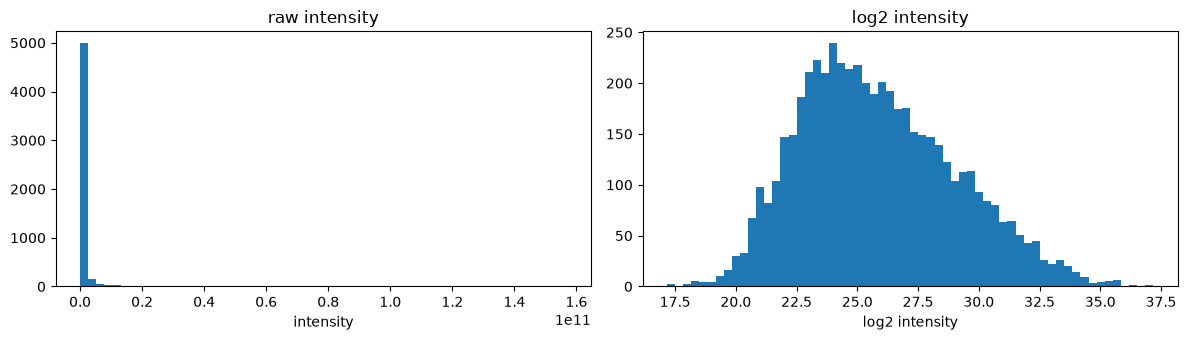

In [3]:
X = np.log2(d[lfq].replace(0, np.nan))          # 0 means "not measured", not "zero protein"

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(d[lfq[0]].replace(0, np.nan).dropna(), bins=60); ax[0].set(title="raw intensity", xlabel="intensity")
ax[1].hist(X[lfq[0]].dropna(), bins=60); ax[1].set(title="log2 intensity", xlabel="log2 intensity")
plt.tight_layout(); plt.show()

## 3 · Missing values

Not every protein is measured in every sample. Look at *which* ones are missing.

missing values per sample:
 LFQ intensity H1    1200
LFQ intensity H2    1045
LFQ intensity H3    1549
LFQ intensity L1    1336
LFQ intensity L2    1175
LFQ intensity L3     859 



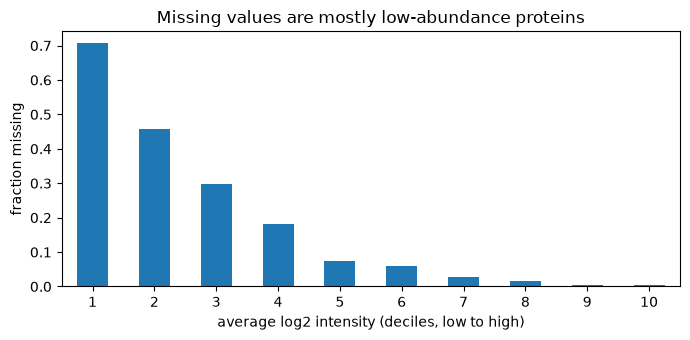

In [4]:
print("missing values per sample:\n", X.isna().sum().to_string(), "\n")

mean_int = X.mean(axis=1)
frac_missing = X.isna().mean(axis=1)
bins = pd.qcut(mean_int, 10)
fig, ax = plt.subplots(figsize=(7, 3.5))
frac_missing.groupby(bins, observed=True).mean().plot(kind="bar", ax=ax)
ax.set(xlabel="average log2 intensity (deciles, low to high)", ylabel="fraction missing",
       title="Missing values are mostly low-abundance proteins")
ax.set_xticklabels(range(1, 11), rotation=0); plt.tight_layout(); plt.show()

Missing values are concentrated among the weakest proteins: most are missing because the protein was
**below the detection limit**, not at random. That matters for what we do about them later.

A protein measured in only one of three replicates cannot be tested fairly, so we keep proteins with
**at least 2 of 3 values in both conditions**.

In [5]:
valid = (X[L].notna().sum(axis=1) >= 2) & (X[H].notna().sum(axis=1) >= 2)
X, d = X[valid], d[valid]
print(f"{len(X)} proteins left ({d.Species.value_counts().to_dict()}), "
      f"{int(X.isna().sum().sum())} missing values remain")

5019 proteins left ({'Human': 3455, 'E. coli': 1564}), 612 missing values remain


## 4 · Normalize — and check the assumption

Samples never contain exactly the same amount of material, so intensities differ between runs for
technical reasons. **Normalization** removes that. The usual way is to shift every sample so that its
median is the same.

That rests on an assumption: **most proteins do not change between the conditions**. Is that true
here? Look at the design again before you run the next cell.

as delivered (MaxLFQ-normalized)    human median log2FC -0.51   E. coli +1.22
median-normalized, all proteins     human median log2FC -0.57   E. coli +1.15
median-normalized, human only       human median log2FC -0.07   E. coli +1.66
expected                            human median log2FC +0.00   E. coli +1.58


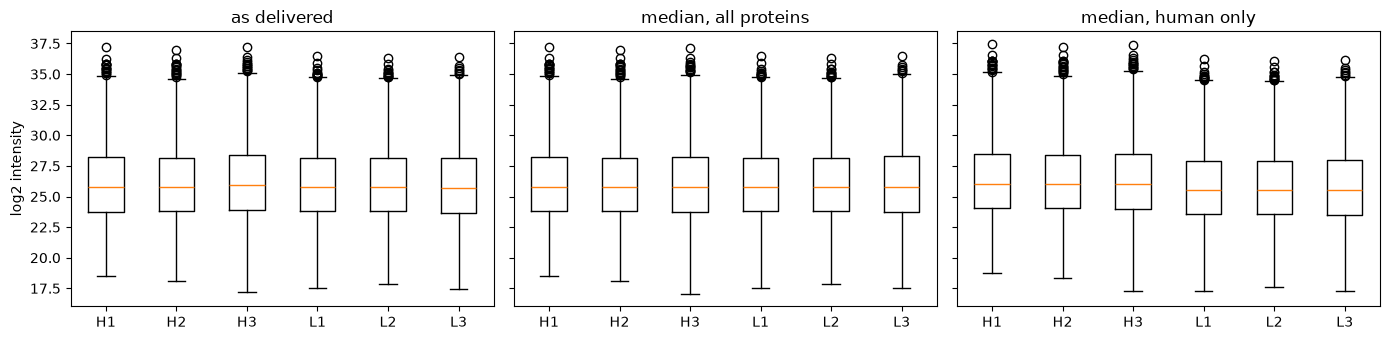

In [6]:
def log2fc(M):
    return M[H].mean(axis=1) - M[L].mean(axis=1)

def report(M, label):
    fc = log2fc(M)
    print(f"{label:34}  human median log2FC {fc[d.Species == 'Human'].median():+.2f}   "
          f"E. coli {fc[d.Species == 'E. coli'].median():+.2f}")

human = d.Species == "Human"
X_all = X - X.median() + X.median().mean()                         # median of all proteins
X_hum = X - X[human].median() + X[human].median().mean()            # median of human proteins only

report(X, "as delivered (MaxLFQ-normalized)")
report(X_all, "median-normalized, all proteins")
report(X_hum, "median-normalized, human only")
print(f"{'expected':34}  human median log2FC +0.00   E. coli +{np.log2(3):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, M, t in zip(ax, (X, X_all, X_hum), ("as delivered", "median, all proteins", "median, human only")):
    a.boxplot([M[c].dropna() for c in lfq]); a.set_title(t)
    a.set_xticks(range(1, len(lfq) + 1)); a.set_xticklabels([c[-2:] for c in lfq])
ax[0].set_ylabel("log2 intensity"); plt.tight_layout(); plt.show()

**Question 3.1** The boxplots of the three versions look almost the same, yet the human fold changes
differ by more than half a log2 unit. Why? What fraction of the proteins in this table are E. coli, and
what happens to the median of an H sample when all of them go up?

**Question 3.2** In a real experiment you do not know which proteins are unchanged. What could you do
instead? (Think of housekeeping proteins, spike-in standards, or asking how many proteins you expect
to change.)

For the rest of the notebook we use the human-only normalization. Change `Xn` below to `X` or
`X_all` later and rerun everything to see what the choice costs.

In [7]:
Xn = X_hum        # try X or X_all here

## 5 · Impute

A t-test needs numbers. Since most missing values are *low* proteins, a common choice (from the
Perseus software) is to fill them with random values drawn from a narrow distribution near the
detection limit: shifted down by 1.8 standard deviations and 0.3 times as wide.

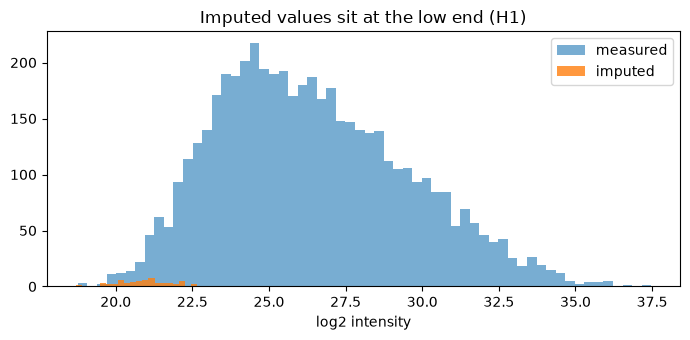

In [8]:
rng = np.random.default_rng(0)
Xi = Xn.copy()
for c in Xi.columns:
    m, s = Xn[c].mean(), Xn[c].std()
    miss = Xi[c].isna()
    Xi.loc[miss, c] = rng.normal(m - 1.8 * s, 0.3 * s, miss.sum())

c = lfq[0]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(Xn[c].dropna(), bins=60, alpha=0.6, label="measured")
ax.hist(Xi.loc[Xn[c].isna(), c], bins=20, alpha=0.8, label="imputed")
ax.set(xlabel="log2 intensity", title=f"Imputed values sit at the low end ({c[-2:]})"); ax.legend()
plt.tight_layout(); plt.show()

## 6 · Do the samples look right?

Before testing anything, check that replicates resemble each other more than they resemble the other
condition.

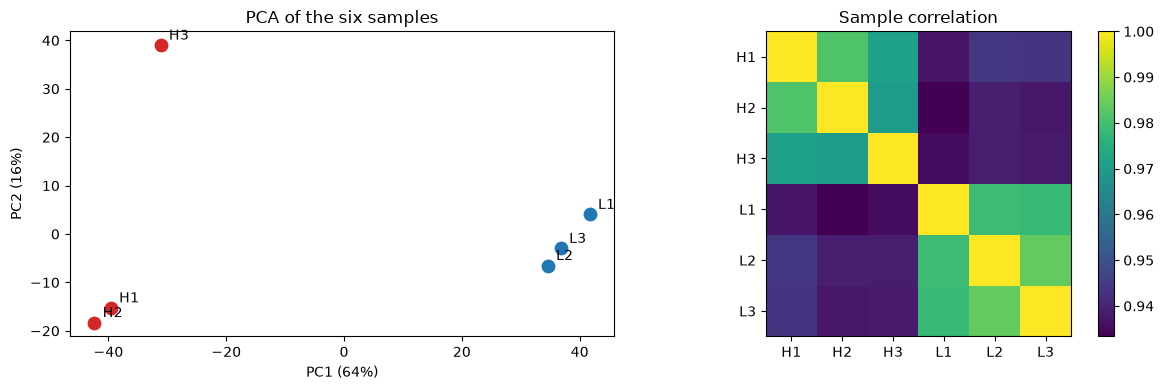

In [9]:
Z = (Xi - Xi.mean(axis=1).values[:, None])                   # centre each protein
u, sv, vt = np.linalg.svd(Z.values, full_matrices=False)      # principal components of the samples
pc = vt[:2].T * sv[:2]
explained = sv**2 / (sv**2).sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (x, y), name in zip(pc, lfq):
    ax[0].scatter(x, y, s=80, color="tab:red" if name[-2] == "H" else "tab:blue")
    ax[0].annotate(name[-2:], (x, y), textcoords="offset points", xytext=(6, 4))
ax[0].set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})", title="PCA of the six samples")
im = ax[1].imshow(Xi.corr(), cmap="viridis"); ax[1].set_title("Sample correlation")
ax[1].set_xticks(range(6)); ax[1].set_xticklabels([c[-2:] for c in lfq])
ax[1].set_yticks(range(6)); ax[1].set_yticklabels([c[-2:] for c in lfq]); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## 7 · Test every protein

A two-sample t-test per protein (Welch's version, which does not assume equal variances), then the
Benjamini–Hochberg correction from Week 4, because we run one test per protein.

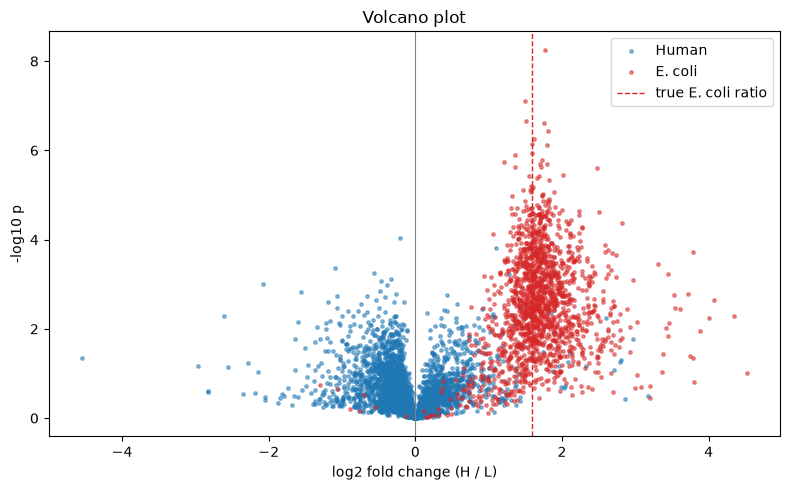

In [10]:
t = stats.ttest_ind(Xi[H], Xi[L], axis=1, equal_var=False)
res = pd.DataFrame({"gene": d["Gene names"].fillna(""), "species": d.Species,
                    "log2FC": log2fc(Xi), "p": t.pvalue})
res["q"] = stats.false_discovery_control(res.p)               # Benjamini-Hochberg
res["significant"] = res.q < 0.05

fig, ax = plt.subplots(figsize=(8, 5))
for sp, col in (("Human", "tab:blue"), ("E. coli", "tab:red")):
    r = res[res.species == sp]
    ax.scatter(r.log2FC, -np.log10(r.p), s=6, alpha=0.5, color=col, label=sp)
ax.axvline(0, color="grey", lw=0.8); ax.axvline(np.log2(3), color="tab:red", ls="--", lw=1, label="true E. coli ratio")
ax.set(xlabel="log2 fold change (H / L)", ylabel="-log10 p", title="Volcano plot"); ax.legend()
plt.tight_layout(); plt.show()

## 8 · Check against the truth

Every significant E. coli protein is a true positive. Every significant human protein is a false
positive. At q < 0.05, we *claimed* that at most 5% of our significant list is wrong.

In [11]:
def score(res, fc_cut=0.0):
    sig = res.significant & (res.log2FC.abs() >= fc_cut)
    tp = int((sig & (res.species == "E. coli")).sum()); fp = int((sig & (res.species == "Human")).sum())
    n_ecoli = int((res.species == "E. coli").sum())
    return dict(fold_change_cutoff=fc_cut, significant=tp + fp, E_coli_found=tp,
                E_coli_total=n_ecoli, human_false_positives=fp,
                actual_FDR=round(fp / max(tp + fp, 1), 3))

pd.DataFrame([score(res, c) for c in (0, 0.5, 1.0)])

,fold_change_cutoff,significant,E_coli_found,E_coli_total,human_false_positives,actual_FDR
0,0.0,1184,1076,1564,108,0.091
1,0.5,1138,1076,1564,62,0.054
2,1.0,1093,1068,1564,25,0.023


**Question 3.3** The Benjamini–Hochberg correction promises an FDR of 5%. Is the *actual* FDR
(human false positives divided by all significant proteins) below 5%? If not, which assumption behind
the test is broken? Go back to step 4, set `Xn = X`, and run everything again.

**Question 3.4** The human false positives that remain have small fold changes. Why does a fold-change
cutoff remove them? Is a protein that changes by 10%, with a p-value of 10⁻⁶, a false positive or a
real but unimportant change?

**Question 3.5** Replace the imputation with nothing: skip step 5, and run the t-test on `Xn` with
`nan_policy="omit"`. Which proteins are affected most, and does the result get better or worse?

**Question 3.6** You now have a list of significant proteins. What would you do with it next to learn
something about biology? (Week 13 comes back to this: enrichment and pathway analysis.)

---
## What to take away

1. Every step — filtering, normalization, imputation, the test, the cutoff — is a choice, and each
   choice changes the list of "significant" proteins.
2. Normalization assumes that most proteins do not change. When that is false, normalization
   *creates* differences that are not there.
3. Missing values in proteomics are mostly missing because a protein was too low to measure.
   Treating them as random is itself an assumption.
4. A corrected p-value controls false positives only if the model behind it is right. Check your
   assumptions on data where you know the answer, before trusting them on data where you do not.